# So sánh hồi quy Logistic và PLA (Perceptron) trên dữ liệu ung thư phổi (mục 4.3.4 e)

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)
DATA = Path('..') / 'data'   # thư mục data/

Tiền xử lý giống notebook 09: chuẩn hóa tên cột, xóa dòng trùng, mã hóa về 0/1

In [2]:
df = pd.read_csv(DATA / "survey lung cancer.csv")
df.columns = df.columns.str.strip()
df = df.drop_duplicates()
df["GENDER"] = (df["GENDER"] == "M").astype(int)
df["LUNG_CANCER"] = (df["LUNG_CANCER"] == "YES").astype(int)
symptoms = df.columns.drop(["GENDER", "AGE", "LUNG_CANCER"])   # các cột triệu chứng
df[symptoms] = df[symptoms] - 1

X = df.drop(columns="LUNG_CANCER")
y = df["LUNG_CANCER"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
perceptron_model = make_pipeline(StandardScaler(),
                                 Perceptron(max_iter=1000, random_state=42)).fit(X_train, y_train)

PLA bằng NumPy: đếm số điểm train bị phân loại sai sau mỗi epoch

In [3]:
scaler = StandardScaler().fit(X_train)
X_train_bar = np.hstack([np.ones((len(X_train), 1)), scaler.transform(X_train)])   # thêm cột 1 cho w0
y_train_pm = np.where(y_train.to_numpy() == 1, 1, -1)   # nhãn PLA: +1 / -1

n_epochs = 50                        # số lần duyệt hết tập train
w = np.zeros(X_train_bar.shape[1])   # trọng số w, khởi tạo 0
pla_errors = []                      # số điểm sai sau mỗi epoch
for epoch in range(n_epochs):
    for i in range(len(y_train_pm)):
        if y_train_pm[i] * (X_train_bar[i] @ w) <= 0:   # điểm i bị phân loại sai
            w = w + y_train_pm[i] * X_train_bar[i]      # cập nhật w <- w + y_i x_i
    pla_errors.append(int(np.sum(np.where(X_train_bar @ w >= 0, 1, -1) != y_train_pm)))
logistic_errors = int(np.sum(model.predict(X_train) != y_train))   # số điểm train sai của Logistic

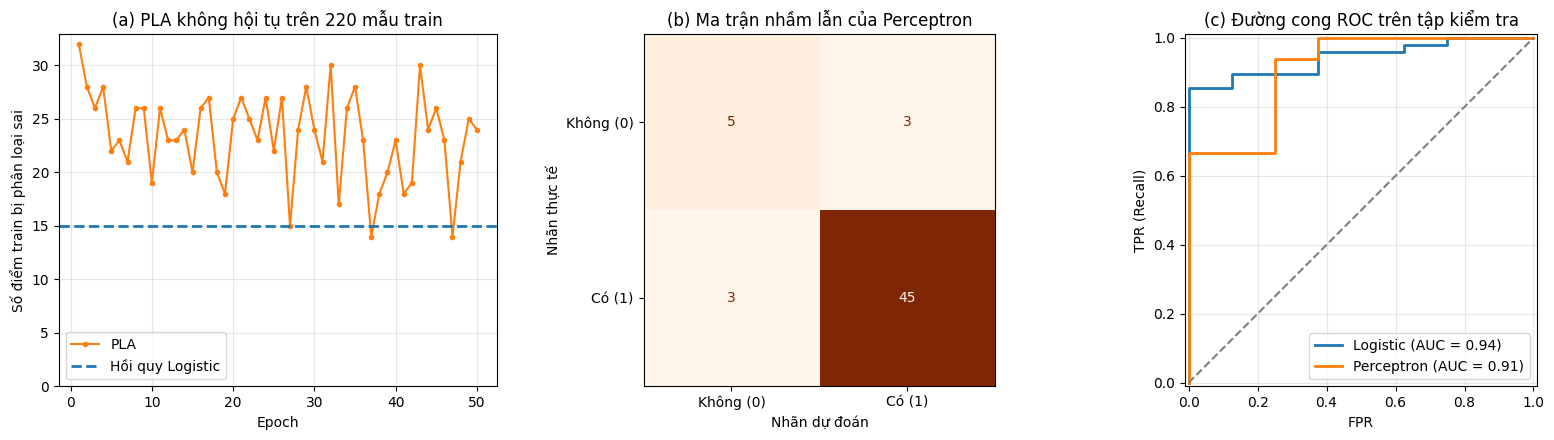

In [4]:
labels = ["Không (0)", "Có (1)"]   # nhãn hiển thị cho hai lớp
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(range(1, n_epochs + 1), pla_errors, "o-", ms=3, color="#FF7F0E", label="PLA")
axes[0].axhline(logistic_errors, ls="--", color="#1F77B4", lw=2, label="Hồi quy Logistic")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Số điểm train bị phân loại sai")
axes[0].set_ylim(bottom=0); axes[0].grid(alpha=0.3); axes[0].legend()
axes[0].set_title("(a) PLA không hội tụ trên 220 mẫu train")

ConfusionMatrixDisplay.from_estimator(perceptron_model, X_test, y_test, display_labels=labels,
                                      cmap="Oranges", colorbar=False, ax=axes[1])
axes[1].set_xlabel("Nhãn dự đoán"); axes[1].set_ylabel("Nhãn thực tế")
axes[1].set_title("(b) Ma trận nhầm lẫn của Perceptron")

RocCurveDisplay.from_estimator(model, X_test, y_test, name="Logistic", ax=axes[2],
                               curve_kwargs=dict(color="#1F77B4", lw=2))
RocCurveDisplay.from_estimator(perceptron_model, X_test, y_test, name="Perceptron", ax=axes[2],
                               curve_kwargs=dict(color="#FF7F0E", lw=2))
axes[2].plot([0, 1], [0, 1], "--", color="#7F7F7F")
axes[2].set_xlabel("FPR"); axes[2].set_ylabel("TPR (Recall)")
axes[2].set_title("(c) Đường cong ROC trên tập kiểm tra"); axes[2].grid(alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES / "lung_cancer_pla.png", dpi=150)